<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)

# 01 · A valid signature is one piece of evidence

**Why can a message have `sig_valid=true` and still need investigation?** We will
use VGI SAML to decode synthetic signed messages, compare signature mathematics
with referenced-content integrity, inspect assertion coverage, and join signer
fingerprints to a separate authored inventory.

The inputs are committed test vectors, never real login tokens. No credentials,
identity provider or service provider is contacted. The output is an evidence audit,
not an authentication decision or a complete SAML validator. An inventory match
cannot detect use of a stolen key that remains in that inventory.

## Choose which synthetic signer is in the inventory

The RSA fixture certificate is always listed. `INCLUDE_EC_SIGNER=False` leaves the
otherwise internally consistent EC-signed fixture outside the inventory. The end
experiment adds that one certificate. Parsing and cryptographic evidence must stay
unchanged. This switch authors test data; real trust cannot be established by copying
a certificate out of an untrusted message. Restart and run all after changing it.

In [1]:
INCLUDE_EC_SIGNER = False

In [2]:
import os

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
import haybarn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.ticker import MaxNLocator
from IPython.display import display
from notebook_support import finish, prose, theme

if type(INCLUDE_EC_SIGNER) is not bool:
    raise ValueError("INCLUDE_EC_SIGNER must be True or False.")
evidence = counts = checks = pd.DataFrame()
theme()
con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-saml/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-saml/notebooks/pyproject.toml.

## Attach the published worker

The visible literal location downloads, verifies and caches the v0.4.0 native
release. No Rust build or repository source is required. All functions below parse
and verify local data; the worker does not obtain a trust store from the network.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
SET TimeZone='UTC';
ATTACH 'saml' (TYPE vgi,LOCATION 'github-auto://Query-farm/vgi-saml@v0.4.0');

,Success


## Keep the complete input population

Eight records include the same RSA message in raw XML and base64, an EC signature,
a changed signed subject, a wrapping fixture with an extra assertion, an unsigned
message, malformed text and SQL NULL. Repeated fixture assertion IDs occur in
separate records; every later join keeps `record_id` in its key.

The XML and base64 fixtures are unchanged copies from the worker's signed test
vectors. Their identities and certificates are synthetic. The base64 example shows
transport normalization; it is not a second independent login or replay detection.

In [4]:
%%sql
CREATE TABLE fixture_files AS SELECT regexp_extract(filename,'([^/]+)$',1) AS file_name,content
FROM read_text(['fixtures/*.xml','fixtures/*.b64']);
CREATE TABLE input_map AS SELECT * FROM (VALUES
 (1,'RSA · XML','signed_response_rsa.xml'),(2,'RSA · base64','signed_response_rsa.b64'),
 (3,'EC · XML','signed_response_ec.xml'),(4,'Changed subject','tampered_response_rsa.xml'),
 (5,'Extra assertion','xsw3_response_rsa.xml'),(6,'Unsigned','unsigned_response.xml')
) t(record_id,label,file_name);
CREATE TABLE messages AS SELECT i.record_id,i.label,f.content AS message
FROM input_map i JOIN fixture_files f USING(file_name)
UNION ALL SELECT 7,'Malformed','<broken'
UNION ALL SELECT 8,'Missing',NULL;
SELECT record_id,label,message IS NOT NULL AS input_supplied,length(message) AS encoded_characters
FROM messages ORDER BY record_id;

,record_id,label,input_supplied,encoded_characters
0,1,RSA · XML,True,4243
1,2,RSA · base64,True,5660
2,3,EC · XML,True,3449
3,4,Changed subject,True,4243
4,5,Extra assertion,True,5997
5,6,Unsigned,True,2161
6,7,Malformed,True,7
7,8,Missing,False,<NA>


## Materialize parsing and signature evidence

`signature()` exposes separate questions: is a signature present; does canonicalization
work; do the reference digests match the referenced content; and does SignatureValue
verify over SignedInfo using the embedded certificate? XML Signature core validation
includes both reference and signature validation. [W3C XML Signature, §3.2](https://www.w3.org/TR/xmldsig-core/#sec-CoreValidation).

The changed-subject fixture leaves SignedInfo and SignatureValue intact, so signature
mathematics can pass while the recomputed content digest fails. Missing input remains
NULL. Malformed input can return false signature fields and an empty anomaly list;
that empty list is not evidence of a valid message.

In [5]:
%%sql
CREATE TABLE parsed AS SELECT *,saml.main.well_formed(message) AS parse,
 saml.main.decode(message) AS decoded,saml.main.signature(message) AS sig,
 saml.main.anomalies(message) AS flags,saml.main.assertions(message) AS assertion_items,
 saml.main.signatures(message) AS signature_items
FROM messages;
SELECT record_id,label,parse.ok AS xml_parsed,parse.kind AS parse_kind,
 decoded.subject AS decoded_subject,decoded.assertion_id AS decoded_assertion,
 sig.signed AS signature_present,sig.c14n_ok AS c14n_ok,sig.digest_ok AS digest_ok,
 sig.sig_valid AS signature_math_ok,flags
FROM parsed ORDER BY record_id;

,record_id,label,xml_parsed,parse_kind,decoded_subject,decoded_assertion,signature_present,c14n_ok,digest_ok,signature_math_ok,flags
0,1,RSA · XML,True,ok,alice@example.com,_a1,True,True,True,True,[]
1,2,RSA · base64,True,ok,alice@example.com,_a1,True,True,True,True,[]
2,3,EC · XML,True,ok,alice@example.com,_a1,True,True,True,True,[]
3,4,Changed subject,True,ok,attacker@evil.com,_a1,True,True,False,True,[digest-mismatch]
4,5,Extra assertion,True,ok,attacker@evil.com,_evil1,True,True,True,True,"[multiple-assertions, signature-covers-other-e..."
5,6,Unsigned,True,ok,alice@example.com,_a1,False,False,False,False,[]
6,7,Malformed,False,truncated,None,None,False,False,False,False,[]
7,8,Missing,<NA>,None,None,None,<NA>,<NA>,<NA>,<NA>,<NA>


## Inspect which assertion the signature references

The wrapping fixture has two assertions. `decode()` returns the first subject, while
the signature references the other assertion. `assertions()` and `signatures()` are
scalar lists: SQL `UNNEST` turns them into inspectable rows.

The equality check below is a diagnostic for these assertion-signed fixtures. It is
not a general XML-signature coverage validator: response-level signatures, duplicate
IDs, reference transforms and other profiles require further validation. Both the
assertion and signature indices remain visible, and joins cannot cross input records.

In [6]:
%%sql
CREATE TABLE assertion_rows AS SELECT p.record_id,p.label,a.idx AS assertion_index,
 a.id AS assertion_id,a.subject,a.parent
FROM parsed p,UNNEST(p.assertion_items) AS _(a);
CREATE TABLE signature_rows AS SELECT p.record_id,s.idx AS signature_index,s.scope,
 s.references_id,s.digest_ok,s.sig_valid
FROM parsed p,UNNEST(p.signature_items) AS _(s);
SELECT a.*,s.signature_index,s.scope,s.references_id,s.digest_ok,s.sig_valid,
 s.signature_index IS NOT NULL AS directly_referenced_in_fixture
FROM assertion_rows a LEFT JOIN signature_rows s
 ON a.record_id=s.record_id AND a.assertion_id=s.references_id
WHERE a.record_id IN (1,4,5) ORDER BY a.record_id,a.assertion_index;

,record_id,label,assertion_index,assertion_id,subject,parent,signature_index,scope,references_id,digest_ok,sig_valid,directly_referenced_in_fixture
0,1,RSA · XML,0,_a1,alice@example.com,Response,0,assertion,_a1,True,True,True
1,4,Changed subject,0,_a1,attacker@evil.com,Response,0,assertion,_a1,False,True,True
2,5,Extra assertion,0,_evil1,attacker@evil.com,Response,<NA>,None,None,<NA>,<NA>,False
3,5,Extra assertion,1,_a1,alice@example.com,Response,0,assertion,_a1,True,True,True


## Join a separately supplied signer inventory

Certificate SHA-256 fingerprints identify the embedded certificate bytes, not their
authorization. Here a small inventory is authored from the fixture's committed
fingerprint files. In a real audit this table needs an independently maintained
source, with issuer, intended use and validity constraints.

The experiment changes inventory membership only. A matching signer does not repair
a failed digest or a structural flag. A stolen key whose certificate remains listed
also matches: this join alone cannot establish that a message was legitimately issued.

In [7]:
%%sql
CREATE TABLE known_signers AS
SELECT trim(content) AS certificate_sha256,'RSA fixture' AS inventory_name
FROM read_text('fixtures/cert_rsa.sha256')
UNION ALL
SELECT trim(content),'EC fixture' FROM read_text('fixtures/cert_ec.sha256')
WHERE {{ INCLUDE_EC_SIGNER }};
CREATE TABLE audit AS SELECT p.*,k.inventory_name,
 CASE WHEN p.sig.signer_cert_sha256 IS NULL THEN NULL
 ELSE k.certificate_sha256 IS NOT NULL END AS signer_in_inventory
FROM parsed p LEFT JOIN known_signers k ON p.sig.signer_cert_sha256=k.certificate_sha256;
SELECT record_id,label,sig.algo AS algorithm,sig.signer_cert_sha256 AS certificate_sha256,
 signer_in_inventory,inventory_name FROM audit ORDER BY record_id;

,record_id,label,algorithm,certificate_sha256,signer_in_inventory,inventory_name
0,1,RSA · XML,RS256,9f9916b1d720793e207a22ec6de0f0fc40b6907d430832...,True,RSA fixture
1,2,RSA · base64,RS256,9f9916b1d720793e207a22ec6de0f0fc40b6907d430832...,True,RSA fixture
2,3,EC · XML,ES256,21b45f117b1a67a32300d524eefde46d111a64ba4bface...,False,None
3,4,Changed subject,RS256,9f9916b1d720793e207a22ec6de0f0fc40b6907d430832...,True,RSA fixture
4,5,Extra assertion,RS256,9f9916b1d720793e207a22ec6de0f0fc40b6907d430832...,True,RSA fixture
5,6,Unsigned,None,None,<NA>,None
6,7,Malformed,None,None,<NA>,None
7,8,Missing,None,None,<NA>,None


In [8]:
%%sql evidence <<
SELECT record_id,label,parse.ok AS xml_parsed,
 CASE WHEN parse.ok THEN sig.signed END AS signature_present,
 CASE WHEN parse.ok AND sig.signed THEN sig.digest_ok END AS content_digest,
 CASE WHEN parse.ok AND sig.signed THEN sig.sig_valid END AS signature_math,
 CASE WHEN parse.ok THEN len(flags)=0 END AS no_reported_flags,
 signer_in_inventory
FROM audit ORDER BY record_id;

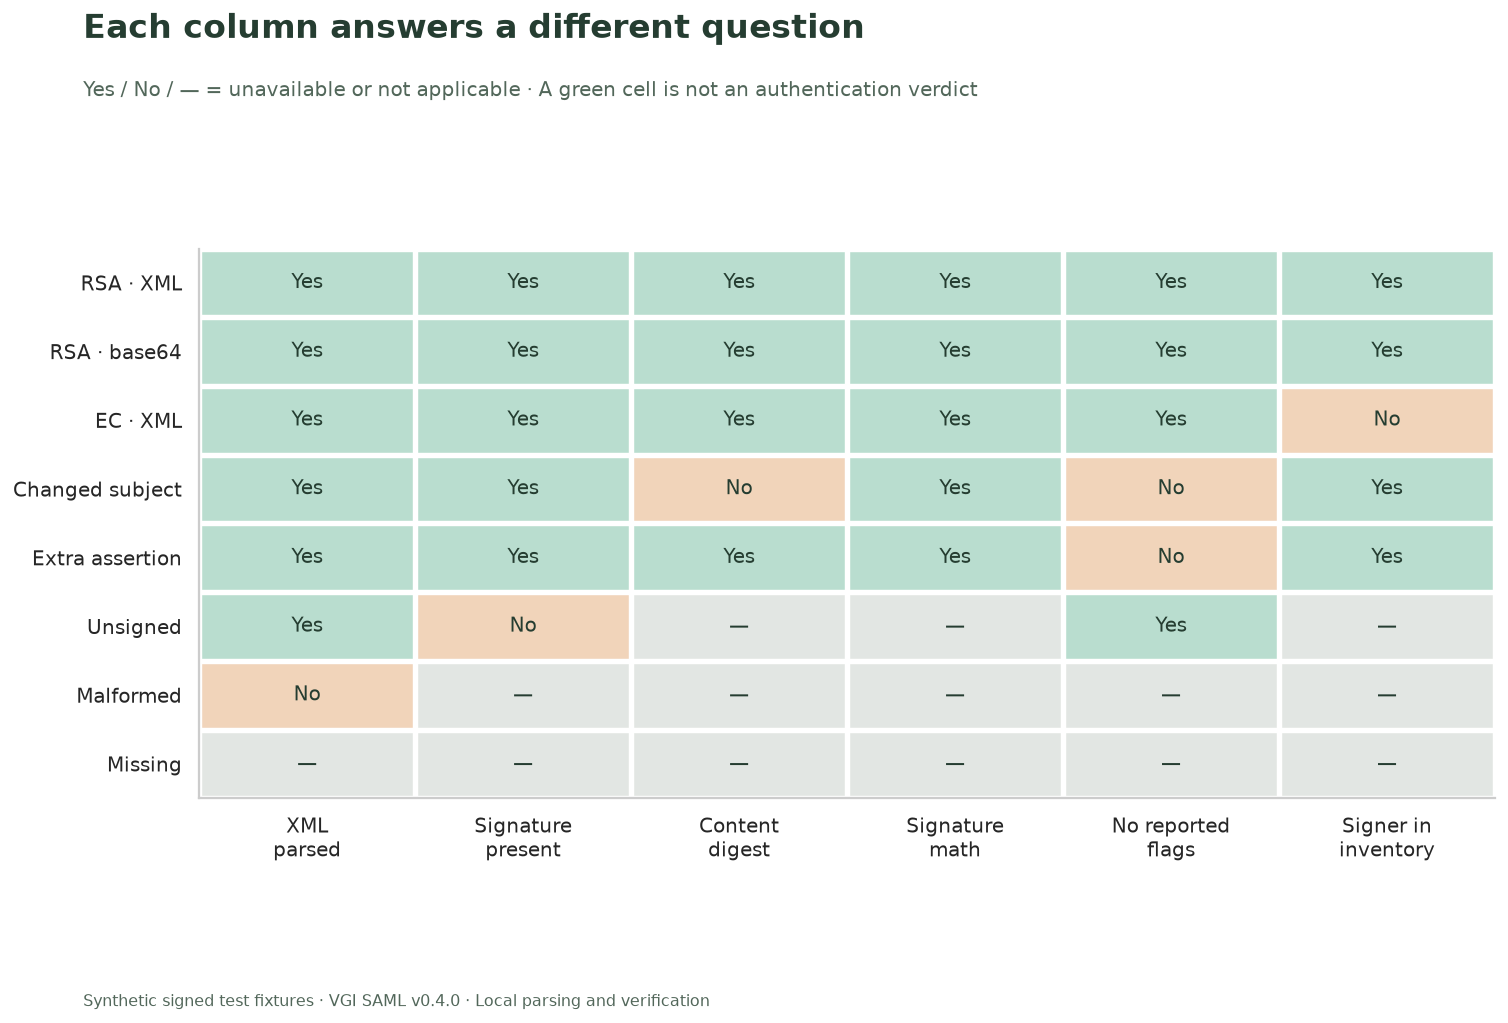

Signature mathematics passes for **5 of 8 input records**. The changed subject still fails its content digest; the extra assertion retains structural flags. The unsigned fixture has no reported flags, demonstrating why that column cannot stand alone.

In [9]:
columns = [
    "xml_parsed",
    "signature_present",
    "content_digest",
    "signature_math",
    "no_reported_flags",
    "signer_in_inventory",
]
labels = [
    "XML\nparsed",
    "Signature\npresent",
    "Content\ndigest",
    "Signature\nmath",
    "No reported\nflags",
    "Signer in\ninventory",
]
values = np.array(
    [
        [0 if pd.isna(v) else 2 if bool(v) else 1 for v in row]
        for row in evidence[columns].itertuples(index=False, name=None)
    ]
)
fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(
    values, cmap=ListedColormap(["#e2e6e3", "#f1d4ba", "#b9ddcf"]), vmin=0, vmax=2, aspect="auto"
)
ax.set_xticks(range(len(labels)), labels)
ax.set_yticks(range(len(evidence)), evidence.label)
ax.set_xticks(np.arange(-0.5, len(labels), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(evidence), 1), minor=True)
ax.grid(False)
ax.grid(which="minor", color="white", linewidth=3)
ax.tick_params(which="minor", bottom=False, left=False)
for y, row in enumerate(values):
    for x, v in enumerate(row):
        ax.text(x, y, ["—", "No", "Yes"][v], ha="center", va="center", fontsize=11, color="#253d31")
finish(
    fig,
    "Each column answers a different question",
    "Yes / No / — = unavailable or not applicable · A green cell is not an authentication verdict",
    "01_evidence_matrix.png",
    bottom=0.14,
)
math_count = int(evidence.signature_math.fillna(False).sum())
prose(
    f"Signature mathematics passes for **{math_count} of {len(evidence)} input records**. "
    "The changed subject still fails its content digest; the extra assertion retains structural flags. "
    "The unsigned fixture has no reported flags, demonstrating why that column cannot stand alone."
)

## Summarize an explicit review order

Assign one category per input so the chart reconciles to all eight records. The order
below is declared policy for this demonstration: preserve missing and parse failures,
then inspect presence, cryptographic checks, structural flags and inventory membership.
It chooses the first reason for review; all evidence remains available above.

“Consistent with listed signer” describes only these checks. The notebook does not
evaluate Conditions time windows, audience, recipient, request correlation, replay,
certificate revocation or a service provider's full SAML profile. In particular,
valid-looking evidence is not sufficient to accept a login.

In [10]:
%%sql
CREATE TABLE review AS SELECT *,CASE
 WHEN message IS NULL THEN 'Missing input'
 WHEN parse.ok IS DISTINCT FROM true THEN 'Parse failed'
 WHEN sig.signed IS DISTINCT FROM true THEN 'No signature'
 WHEN sig.c14n_ok IS DISTINCT FROM true OR sig.digest_ok IS DISTINCT FROM true
   OR sig.sig_valid IS DISTINCT FROM true THEN 'Cryptographic check failed'
 WHEN len(flags)>0 THEN 'Structural flags present'
 WHEN signer_in_inventory IS DISTINCT FROM true THEN 'Signer outside inventory'
 ELSE 'Consistent with listed signer' END AS review_category
FROM audit;
SELECT record_id,label,review_category FROM review ORDER BY record_id;

,record_id,label,review_category
0,1,RSA · XML,Consistent with listed signer
1,2,RSA · base64,Consistent with listed signer
2,3,EC · XML,Signer outside inventory
3,4,Changed subject,Cryptographic check failed
4,5,Extra assertion,Structural flags present
5,6,Unsigned,No signature
6,7,Malformed,Parse failed
7,8,Missing,Missing input


In [11]:
%%sql counts <<
WITH categories AS (SELECT * FROM (VALUES
 (1,'Missing input'),(2,'Parse failed'),(3,'No signature'),(4,'Cryptographic check failed'),
 (5,'Structural flags present'),(6,'Signer outside inventory'),(7,'Consistent with listed signer')
) t(sort_order,review_category))
SELECT c.sort_order,c.review_category,count(r.record_id) AS records
FROM categories c LEFT JOIN review r USING(review_category)
GROUP BY c.sort_order,c.review_category ORDER BY c.sort_order;

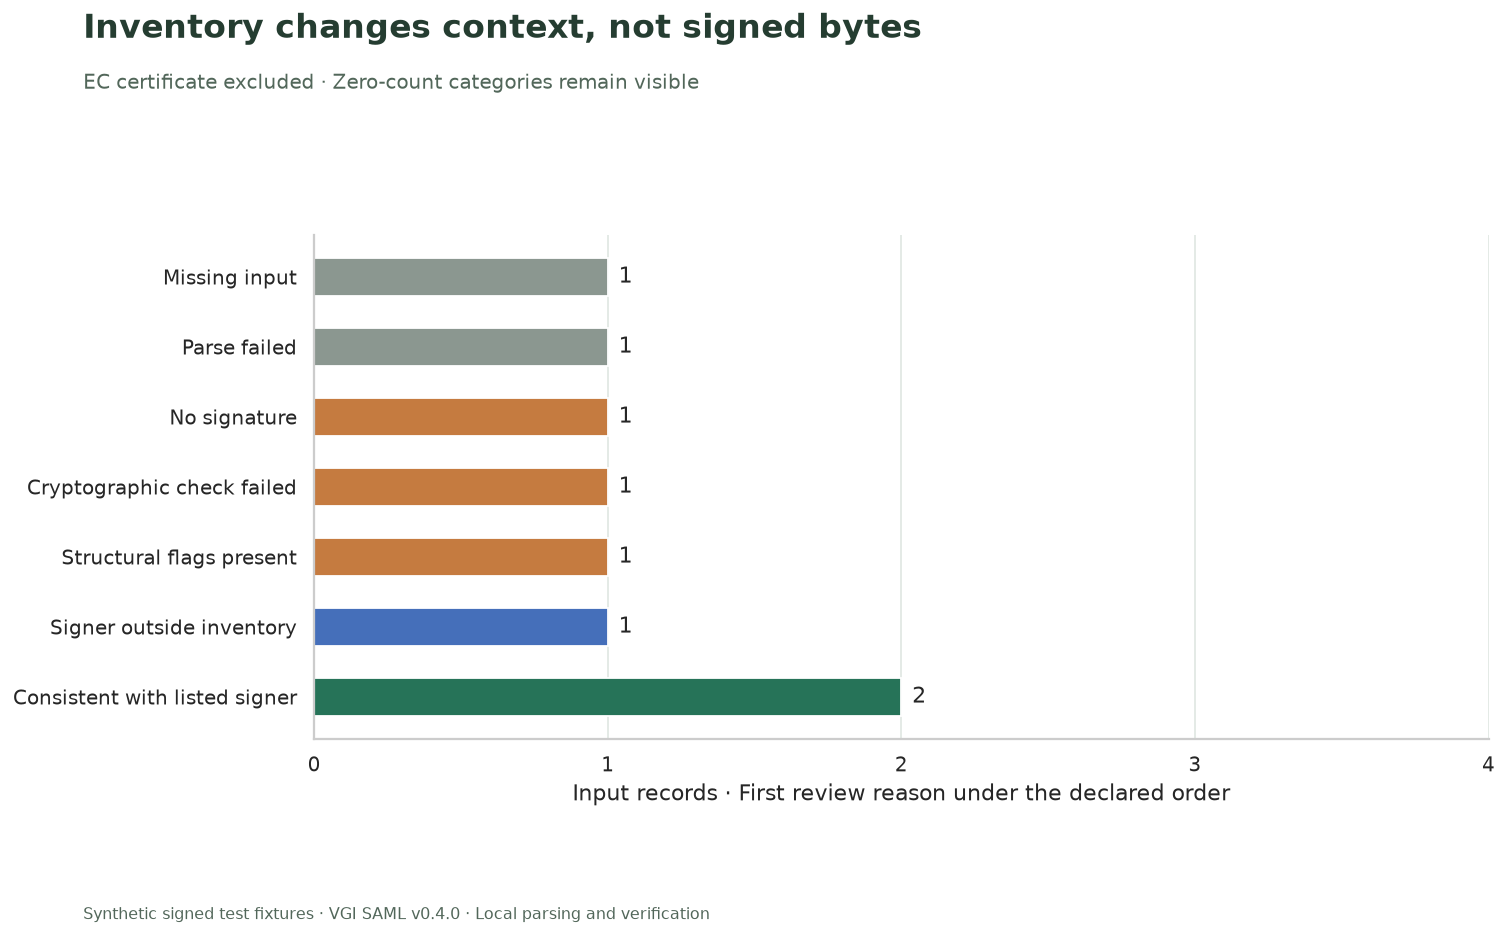

**2 records** are internally consistent with a listed signer under these limited checks; **1** otherwise consistent record(s) have a signer outside the inventory. The tampered and wrapping fixtures still need review even though their RSA signer is listed.

,review_category,records
0,Missing input,1
1,Parse failed,1
2,No signature,1
3,Cryptographic check failed,1
4,Structural flags present,1
5,Signer outside inventory,1
6,Consistent with listed signer,2


In [12]:
fig, ax = plt.subplots(figsize=(12, 7.3))
colors = ["#8b9790", "#8b9790", "#c57b40", "#c57b40", "#c57b40", "#456fba", "#267358"]
bars = ax.barh(counts.review_category, counts.records, color=colors, height=0.55)
ax.bar_label(bars, padding=6, fontsize=12)
ax.invert_yaxis()
ax.set_xlim(0, 4)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlabel("Input records · First review reason under the declared order")
ax.grid(axis="y", visible=False)
finish(
    fig,
    "Inventory changes context, not signed bytes",
    f"EC certificate {'included' if INCLUDE_EC_SIGNER else 'excluded'} · Zero-count categories remain visible",
    "02_review_population.png",
    bottom=0.12,
)
consistent = int(
    counts.loc[counts.review_category == "Consistent with listed signer", "records"].iloc[0]
)
unknown = int(counts.loc[counts.review_category == "Signer outside inventory", "records"].iloc[0])
prose(
    f"**{consistent} records** are internally consistent with a listed signer under these limited checks; "
    f"**{unknown}** otherwise consistent record(s) have a signer outside the inventory. "
    "The tampered and wrapping fixtures still need review even though their RSA signer is listed."
)
display(counts[["review_category", "records"]])

## Reconcile inputs and validate the distinctions

These assertions check the pinned release's behavior on the committed synthetic
vectors and the notebook's joins. They are not a certification of a production SAML
authentication flow. Raw XML and its base64 wrapper must decode to the same evidence.

In [13]:
%%sql checks <<
SELECT 'All eight inputs survive every one-row audit' AS check_name,
 (SELECT count(*)=8 AND count(DISTINCT record_id)=8 FROM review) AS passed
UNION ALL SELECT 'Raw XML and base64 preserve decoded and signature evidence',
 (SELECT a.decoded=b.decoded AND a.sig=b.sig AND a.flags=b.flags FROM parsed a,parsed b WHERE a.record_id=1 AND b.record_id=2)
UNION ALL SELECT 'Changed content has passing signature math and failing digest',
 (SELECT sig.sig_valid AND NOT sig.digest_ok AND list_contains(flags,'digest-mismatch') FROM parsed WHERE record_id=4)
UNION ALL SELECT 'Extra assertion retains signature math, digest and structural flags',
 (SELECT sig.sig_valid AND sig.digest_ok AND decoded.assertion_count=2
 AND list_contains(flags,'multiple-assertions') FROM parsed WHERE record_id=5)
UNION ALL SELECT 'Wrapping fixture first assertion is not the referenced assertion',
 (SELECT p.decoded.assertion_id<>s.references_id FROM parsed p JOIN signature_rows s USING(record_id) WHERE record_id=5)
UNION ALL SELECT 'Only one of the two wrapping assertions is directly referenced',
 (SELECT count(*)=1 FROM assertion_rows a JOIN signature_rows s ON a.record_id=s.record_id AND a.assertion_id=s.references_id WHERE a.record_id=5)
UNION ALL SELECT 'Unsigned message has no flags but no signature',
 (SELECT NOT sig.signed AND len(flags)=0 FROM parsed WHERE record_id=6)
UNION ALL SELECT 'Malformed input remains a parse failure even with no flags',
 (SELECT NOT parse.ok AND len(flags)=0 AND review_category='Parse failed' FROM review WHERE record_id=7)
UNION ALL SELECT 'Missing input preserves NULL function outputs',
 (SELECT parse IS NULL AND decoded IS NULL AND sig IS NULL AND flags IS NULL FROM parsed WHERE record_id=8)
UNION ALL SELECT 'Inventory membership follows only the experiment',
 (SELECT signer_in_inventory={{ INCLUDE_EC_SIGNER }} FROM audit WHERE record_id=3)
UNION ALL SELECT 'Known RSA signer does not override earlier review evidence',
 (SELECT count(*)=2 AND bool_and(signer_in_inventory) FROM review WHERE record_id IN (4,5) AND review_category IN ('Cryptographic check failed','Structural flags present'))
UNION ALL SELECT 'Inventory keys are unique and independently supplied',
 (SELECT count(*)=count(DISTINCT certificate_sha256) AND count(*)=1+CAST({{ INCLUDE_EC_SIGNER }} AS INTEGER) FROM known_signers);

In [14]:
assert checks.passed.all(), checks.loc[~checks.passed].to_dict("records")
assert (
    int(counts.records.sum())
    == len(evidence)
    == con.execute("SELECT count(*) FROM messages").fetchone()[0]
)
prose(
    f"**{len(checks)} SQL checks and the eight-record reconciliation passed.** Evidence is retained before review categories are assigned."
)

**12 SQL checks and the eight-record reconciliation passed.** Evidence is retained before review categories are assigned.

## Experiment · add the EC certificate to the fixture inventory

Change only `INCLUDE_EC_SIGNER` to **True**, restart, and run all. Predict which matrix
cell and category change. The parsed subject, signature mathematics, digest and
structural flags should be identical; adding an inventory row does not change the
signed bytes or repair a message.

The exercise illustrates the separate roles of message evidence and externally
supplied context. It does not establish trust in a real certificate. Reset the
parameter to `False` for the saved default.

In [15]:
con.close()
plt.close("all")

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)